In [4]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_global_ecommerce_data.csv to cleaned_global_ecommerce_data.csv


In [5]:
import pandas as pd
df = pd.read_csv("/content/cleaned_global_ecommerce_data.csv")

In [6]:
df.head()

,Transaction_ID,Date,Customer_ID,Customer_Age,Gender,Location,Product_Category,Product_Name,Unit_Price,Quantity,Discount_Applied,Total_Revenue,Payment_Method,Delivery_Time_Days,Customer_Rating
0,TXN1000,2023-01-01,CUST_4764,39,Male,Pakistan,Apparel,Cotton T-Shirt,89.50,3,0.04,257.76,PayPal,8,3.3
1,TXN1001,2023-01-01,CUST_20831,33,Male,Germany,Electronics,4K Smart TV,1129.50,3,0.05,3219.07,Credit Card,9,3.8
2,TXN1002,2023-01-01,CUST_15374,41,Non-binary,Germany,Home & Kitchen,Air Fryer,195.79,2,0.13,340.67,Credit Card,14,1.5
3,TXN1003,2023-01-01,CUST_17541,50,Non-binary,UAE,Electronics,Gaming Laptop,1153.43,1,0.10,1038.09,Bank Transfer,11,1.6
4,TXN1004,2023-01-01,CUST_14124,32,Male,UAE,Apparel,Formal Shirt,146.54,2,0.08,269.63,Credit Card,6,4.5


# Data Cleaning


In [8]:
df.isnull().sum()

,0
Transaction_ID,0
Date,0
Customer_ID,0
Customer_Age,0
Gender,0
Location,0
Product_Category,0
Product_Name,0
Unit_Price,0
Quantity,0


In [9]:
print(df.shape)
df.info()

(50000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      50000 non-null  object 
 1   Date                50000 non-null  object 
 2   Customer_ID         50000 non-null  object 
 3   Customer_Age        50000 non-null  int64  
 4   Gender              50000 non-null  object 
 5   Location            50000 non-null  object 
 6   Product_Category    50000 non-null  object 
 7   Product_Name        50000 non-null  object 
 8   Unit_Price          50000 non-null  float64
 9   Quantity            50000 non-null  int64  
 10  Discount_Applied    50000 non-null  float64
 11  Total_Revenue       50000 non-null  float64
 12  Payment_Method      50000 non-null  object 
 13  Delivery_Time_Days  50000 non-null  int64  
 14  Customer_Rating     50000 non-null  float64
dtypes: float64(4), int64(3), object(8)
memory

In [10]:
df_clean = df.copy()
df_clean['Date'] = pd.to_datetime(df_clean['Date'])
print(df_clean['Date'].dtype, df_clean['Date'].min(), df_clean['Date'].max())

datetime64[ns] 2023-01-01 00:00:00 2026-06-01 00:00:00


In [11]:
text_cols = ['Transaction_ID','Customer_ID','Gender','Location',
             'Product_Category','Product_Name','Payment_Method']
for c in text_cols:
    df_clean[c] = df_clean[c].str.strip()

for c in ['Gender','Location','Product_Category','Payment_Method']:
    print(c, df_clean[c].unique())

Gender ['Male' 'Non-binary' 'Female']
Location ['Pakistan' 'Germany' 'UAE' 'USA' 'UK' 'India']
Product_Category ['Apparel' 'Electronics' 'Home & Kitchen' 'Sports' 'Beauty']
Payment_Method ['PayPal' 'Credit Card' 'Bank Transfer' 'Crypto']


In [13]:
num_cols = ['Customer_Age','Unit_Price','Quantity','Discount_Applied',
            'Total_Revenue','Delivery_Time_Days','Customer_Rating']
print(df_clean[num_cols].agg(['min','max']).T)

                      min      max
Customer_Age        18.00    70.00
Unit_Price           5.00  1499.99
Quantity             1.00     5.00
Discount_Applied     0.00     0.30
Total_Revenue        4.67  6373.34
Delivery_Time_Days   1.00    15.00
Customer_Rating      1.00     5.00


In [15]:
def iqr_flag(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)

df_clean['Revenue_Outlier'] = df_clean.groupby('Product_Category')['Total_Revenue'].transform(iqr_flag)
print(df_clean['Revenue_Outlier'].sum(), "outlier orders")

648 outlier orders


In [16]:
print(df_clean.shape, df_clean.isnull().sum().sum())
df_clean.info()

(50000, 16) 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Transaction_ID      50000 non-null  object        
 1   Date                50000 non-null  datetime64[ns]
 2   Customer_ID         50000 non-null  object        
 3   Customer_Age        50000 non-null  int64         
 4   Gender              50000 non-null  object        
 5   Location            50000 non-null  object        
 6   Product_Category    50000 non-null  object        
 7   Product_Name        50000 non-null  object        
 8   Unit_Price          50000 non-null  float64       
 9   Quantity            50000 non-null  int64         
 10  Discount_Applied    50000 non-null  float64       
 11  Total_Revenue       50000 non-null  float64       
 12  Payment_Method      50000 non-null  object        
 13  Delivery_Time_Days  50000 non-nu

In [17]:
# Duplicates
print("Fully duplicated rows:", df_clean.duplicated().sum())
print("Duplicate Transaction_IDs:", df_clean['Transaction_ID'].duplicated().sum())

Fully duplicated rows: 0
Duplicate Transaction_IDs: 0


In [18]:
# Revenue reconciliation
expected = df_clean['Unit_Price'] * df_clean['Quantity'] * (1 - df_clean['Discount_Applied'])
bad = ((expected - df_clean['Total_Revenue']).abs() > 0.011).sum()
print("Rows where revenue doesn't reconcile:", bad)

Rows where revenue doesn't reconcile: 0


In [19]:
# Customer_ID consistency
g = df_clean.groupby('Customer_ID').agg(
    orders=('Transaction_ID','count'),
    ages=('Customer_Age','nunique'),
    genders=('Gender','nunique'))
print("Unique customers:", len(g))
print("With more than one age:", (g['ages'] > 1).sum())
print("With more than one gender:", (g['genders'] > 1).sum())

Unique customers: 18352
With more than one age: 14093
With more than one gender: 11112


In [20]:
# Why outliers are flagged per category, not dataset-wide
for c in ['Unit_Price', 'Total_Revenue']:
    print(c, "dataset-wide IQR outliers:", iqr_flag(df_clean[c]).sum())
print(df_clean.groupby('Product_Category')['Unit_Price'].agg(['min','max']))

Unit_Price dataset-wide IQR outliers: 8717
Total_Revenue dataset-wide IQR outliers: 6793
                    min      max
Product_Category                
Apparel           10.01   149.99
Beauty             5.00    80.00
Electronics       50.02  1499.99
Home & Kitchen    30.01   299.98
Sports            15.00   199.89


In [38]:
print({c: int((df[c] != df_clean[c]).sum()) for c in text_cols})   # expect all 0

{'Transaction_ID': 0, 'Customer_ID': 0, 'Gender': 0, 'Location': 0, 'Product_Category': 0, 'Product_Name': 0, 'Payment_Method': 0}


# Feature Engineering


In [21]:
import numpy as np

# Time features
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Month_Name'] = df_clean['Date'].dt.strftime('%b')
df_clean['Quarter'] = 'Q' + df_clean['Date'].dt.quarter.astype(str)
df_clean['Month_Start'] = df_clean['Date'].dt.to_period('M').dt.to_timestamp()
df_clean['Season'] = np.where(df_clean['Month_Num'].isin([11, 12]), 'Peak (Nov-Dec)', 'Regular (Jan-Oct)')

# Customer and order segments
df_clean['Age_Group'] = pd.cut(df_clean['Customer_Age'], bins=[17,24,34,44,54,70],
                               labels=['18-24','25-34','35-44','45-54','55+'])
df_clean['Delivery_Bucket'] = pd.cut(df_clean['Delivery_Time_Days'], bins=[0,3,7,10,15],
                               labels=['1-3 days','4-7 days','8-10 days','11-15 days'])
df_clean['Delivery_Status'] = np.where(df_clean['Delivery_Time_Days'] >= 11,
                               'Late (11+ days)', 'On time (1-10 days)')
df_clean['Discount_Band'] = pd.cut(df_clean['Discount_Applied'], bins=[-0.001,0.05,0.10,0.15,0.20,0.30],
                               labels=['0-5%','6-10%','11-15%','16-20%','21-30%'])

# Calculated money fields
df_clean['Revenue_Before_Discount'] = (df_clean['Unit_Price'] * df_clean['Quantity']).round(2)
df_clean['Discount_Amount'] = (df_clean['Revenue_Before_Discount'] - df_clean['Total_Revenue']).round(2)
df_clean['Net_Price_Per_Unit'] = (df_clean['Total_Revenue'] / df_clean['Quantity']).round(2)

print(df_clean.shape, df_clean.isnull().sum().sum())
print(df_clean['Delivery_Bucket'].value_counts().sort_index())

(50000, 29) 0
Delivery_Bucket
1-3 days      10011
4-7 days      13338
8-10 days      9995
11-15 days    16656
Name: count, dtype: int64


In [24]:
drop_cols = ['Customer_ID', 'Customer_Age', 'Month_Name', 'Quarter']
df_final = df_clean.drop(columns=drop_cols)

print(df_final.shape)                  # expect (50000, 25)
print(df_final.isnull().sum().sum())   # expect 0
print(df_final.columns.tolist())

(50000, 25)
0
['Transaction_ID', 'Date', 'Gender', 'Location', 'Product_Category', 'Product_Name', 'Unit_Price', 'Quantity', 'Discount_Applied', 'Total_Revenue', 'Payment_Method', 'Delivery_Time_Days', 'Customer_Rating', 'Revenue_Outlier', 'Year', 'Month_Num', 'Month_Start', 'Season', 'Age_Group', 'Delivery_Bucket', 'Delivery_Status', 'Discount_Band', 'Revenue_Before_Discount', 'Discount_Amount', 'Net_Price_Per_Unit']


In [27]:
df_final.to_csv("processed_ecommerce_data.csv", index=False)
from google.colab import files
files.download("processed_ecommerce_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# EDA

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option('display.float_format', '{:,.2f}'.format)
d = df_final
BLUE, RED, GREY = '#4a6fa5', '#c0392b', '#9aa5b1'

Season  Peak (Nov-Dec)  Regular (Jan-Oct)  Peak_Share_%
Year                                                   
2023      4,449,574.10       5,231,683.41         46.00
2024      4,191,763.76       5,401,529.35         43.70
2025      4,414,944.58       5,623,480.14         44.00
                   Orders       Revenue    AOV  Avg_Qty  Avg_Discount
Season                                                               
Peak (Nov-Dec)      15928 13,056,282.44 819.71     3.49          0.22
Regular (Jan-Oct)   29207 16,256,692.90 556.60     2.01          0.07


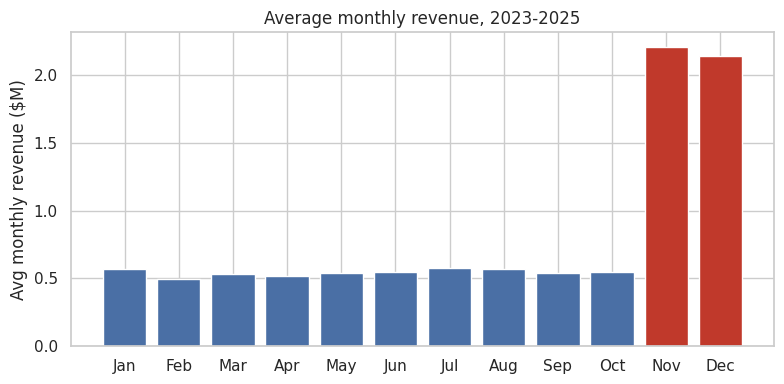

In [29]:
full = d[d['Date'] < '2026-01-01']                      # full years only
yr = full.groupby(['Year','Season'])['Total_Revenue'].sum().unstack()
yr['Peak_Share_%'] = (yr['Peak (Nov-Dec)'] / yr.sum(axis=1) * 100).round(1)
print(yr)
print(full.groupby('Season').agg(Orders=('Transaction_ID','size'), Revenue=('Total_Revenue','sum'),
      AOV=('Total_Revenue','mean'), Avg_Qty=('Quantity','mean'), Avg_Discount=('Discount_Applied','mean')))

monthly = full.groupby(['Year','Month_Num'])['Total_Revenue'].sum().groupby('Month_Num').mean() / 1e6
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(monthly.index, monthly.values, color=[RED if m in (11,12) else BLUE for m in monthly.index])
ax.set_xticks(range(1,13))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_ylabel('Avg monthly revenue ($M)'); ax.set_title('Average monthly revenue, 2023-2025')
plt.tight_layout(); plt.show()

                       Revenue  Orders      AOV  Rev_Share_%  Order_Share_%
Product_Category                                                           
Electronics      24,824,547.71   15018 1,652.99        77.30          30.00
Home & Kitchen    2,905,955.24    8297   350.24         9.00          16.60
Apparel           2,096,210.65   12299   170.44         6.50          24.60
Sports            1,663,166.49    7368   225.73         5.20          14.70
Beauty              636,456.35    7018    90.69         2.00          14.00
Product_Name
Smartphone 128GB                      15.90
4K Smart TV                           15.90
Wireless Noise-Canceling Headphones   15.50
Gaming Laptop                         15.00
Smartwatch                            14.90
Air Fryer                              1.90
Name: Total_Revenue, dtype: float64


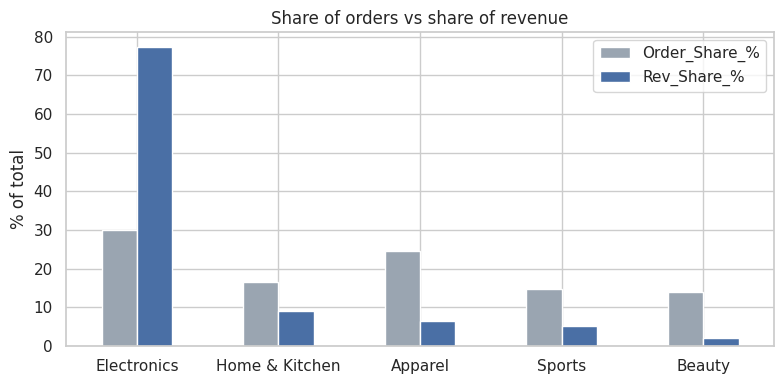

In [30]:
c = d.groupby('Product_Category').agg(Revenue=('Total_Revenue','sum'),
      Orders=('Transaction_ID','size'), AOV=('Total_Revenue','mean'))
c['Rev_Share_%'] = (c['Revenue']/c['Revenue'].sum()*100).round(1)
c['Order_Share_%'] = (c['Orders']/c['Orders'].sum()*100).round(1)
c = c.sort_values('Revenue', ascending=False)
print(c)
p = d.groupby('Product_Name')['Total_Revenue'].sum().sort_values(ascending=False)
print((p/p.sum()*100).round(1).head(6))

c[['Order_Share_%','Rev_Share_%']].plot(kind='bar', figsize=(8,4), color=[GREY, BLUE])
plt.ylabel('% of total'); plt.xlabel(''); plt.xticks(rotation=0)
plt.title('Share of orders vs share of revenue'); plt.tight_layout(); plt.show()

Delivery_Time_Days
1    3.99
2    3.97
3    3.98
4    3.97
5    3.97
6    3.98
7    3.98
8    3.97
9    3.98
10   3.99
11   2.04
12   2.03
13   2.03
14   2.01
15   2.02
Name: Customer_Rating, dtype: float64
                     Orders  Avg_Rating  Pct_Rated_Below_3
Delivery_Status                                           
Late (11+ days)       16656        2.03              95.20
On time (1-10 days)   33344        3.98               0.00
Delivery_Status  Late (11+ days)  On time (1-10 days)
Location                                             
Germany                    32.30                67.70
India                      34.00                66.00
Pakistan                   33.30                66.70
UAE                        33.80                66.20
UK                         32.90                67.10
USA                        33.60                66.40


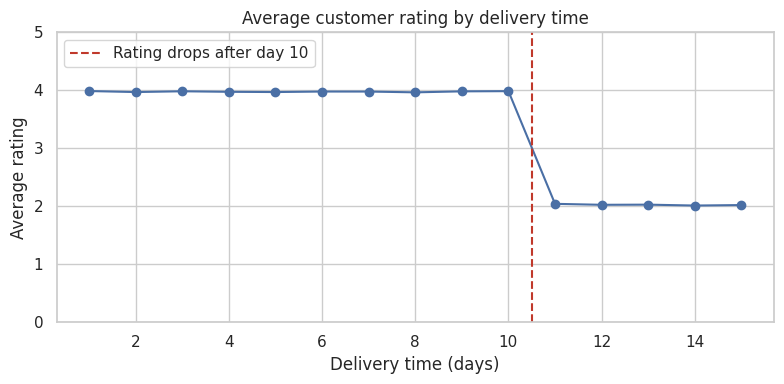

In [31]:
by_day = d.groupby('Delivery_Time_Days')['Customer_Rating'].mean()
print(by_day.round(2))
print(d.groupby('Delivery_Status').agg(Orders=('Transaction_ID','size'),
      Avg_Rating=('Customer_Rating','mean'),
      Pct_Rated_Below_3=('Customer_Rating', lambda s: (s<3).mean()*100)))
print((pd.crosstab(d['Location'], d['Delivery_Status'], normalize='index')*100).round(1))

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(by_day.index, by_day.values, marker='o', color=BLUE)
ax.axvline(10.5, color=RED, linestyle='--', label='Rating drops after day 10')
ax.set_ylim(0,5); ax.set_xlabel('Delivery time (days)'); ax.set_ylabel('Average rating')
ax.set_title('Average customer rating by delivery time'); ax.legend()
plt.tight_layout(); plt.show()

               Orders  Avg_Qty    AOV  Rating  Net_Price_Per_Unit
Discount_Band                                                    
0-5%            12473     2.02 591.76    3.34              291.22
6-10%           11461     2.01 562.68    3.31              279.85
11-15%          10626     2.08 531.57    3.33              257.97
16-20%           5431     3.49 894.82    3.35              253.26
21-30%          10009     3.49 778.12    3.32              222.40
          mean  min  max
Quantity                
1         0.08 0.00 0.15
2         0.11 0.00 0.30
3         0.11 0.00 0.30
4         0.22 0.15 0.30
5         0.22 0.15 0.30
Total discount given: 5299282 | % of pre-discount sales: 14.2


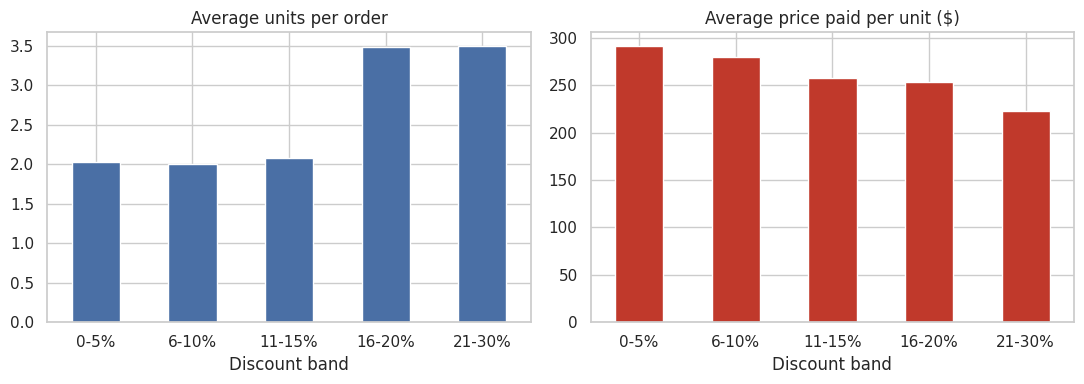

In [32]:
g = d.groupby('Discount_Band', observed=True).agg(Orders=('Transaction_ID','size'),
      Avg_Qty=('Quantity','mean'), AOV=('Total_Revenue','mean'),
      Rating=('Customer_Rating','mean'), Net_Price_Per_Unit=('Net_Price_Per_Unit','mean'))
print(g)
print(d.groupby('Quantity')['Discount_Applied'].agg(['mean','min','max']))
tot = d['Discount_Amount'].sum()
print('Total discount given:', round(tot), '| % of pre-discount sales:',
      round(tot/d['Revenue_Before_Discount'].sum()*100, 1))

fig, axes = plt.subplots(1, 2, figsize=(11,4))
g['Avg_Qty'].plot(kind='bar', ax=axes[0], color=BLUE); axes[0].set_title('Average units per order')
g['Net_Price_Per_Unit'].plot(kind='bar', ax=axes[1], color=RED); axes[1].set_title('Average price paid per unit ($)')
for ax in axes: ax.set_xlabel('Discount band'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

In [39]:
print(d.groupby(['Season','Quantity'])['Discount_Applied'].agg(['mean','min','max','size']).round(3))
for s, x in d.groupby('Season'):
    print(s, 'corr discount vs quantity:', round(x['Discount_Applied'].corr(x['Quantity']), 3))
print(d.groupby(['Season','Discount_Band'], observed=True).agg(Orders=('Transaction_ID','size'),
      Avg_Qty=('Quantity','mean'), AOV=('Total_Revenue','mean'), Unit_Price=('Unit_Price','mean')).round(2))
print('Outlier orders in Nov-Dec:', d.loc[d['Revenue_Outlier'],'Season'].str.startswith('Peak').mean())

                            mean  min  max   size
Season            Quantity                       
Peak (Nov-Dec)    2         0.22 0.15 0.30   3983
                  3         0.23 0.15 0.30   4043
                  4         0.23 0.15 0.30   3991
                  5         0.22 0.15 0.30   3911
Regular (Jan-Oct) 1         0.07 0.00 0.15  11172
                  2         0.08 0.00 0.15  11333
                  3         0.07 0.00 0.15  11567
Peak (Nov-Dec) corr discount vs quantity: 0.002
Regular (Jan-Oct) corr discount vs quantity: -0.009
                                 Orders  Avg_Qty    AOV  Unit_Price
Season            Discount_Band                                    
Peak (Nov-Dec)    11-15%            488     3.52 836.67      286.47
                  16-20%           5431     3.49 894.82      308.80
                  21-30%          10009     3.49 778.12      297.25
Regular (Jan-Oct) 0-5%            12473     2.02 591.76      299.37
                  6-10%           11461   

           Orders       Revenue    AOV  Rev_Share_%  Order_Share_%
Age_Group                                                         
18-24        7920  6,148,425.56 776.32        19.10          15.80
25-34       17048 13,308,800.20 780.67        41.40          34.10
35-44       17091  9,055,555.45 529.84        28.20          34.20
45-54        6824  3,144,628.90 460.82         9.80          13.60
55+          1117    468,926.33 419.81         1.50           2.20
Product_Category  Apparel  Beauty  Electronics  Home & Kitchen  Sports
Age_Group                                                             
18-24               29.00   10.00        40.00           10.00   10.00
25-34               30.00   10.00        40.00           10.00   10.00
35-44               21.00   19.00        22.00           19.00   19.00
45-54               17.00   17.00        16.00           30.00   21.00
55+                 10.00    9.00        11.00           49.00   20.00
Product_Category  Apparel  Beauty 

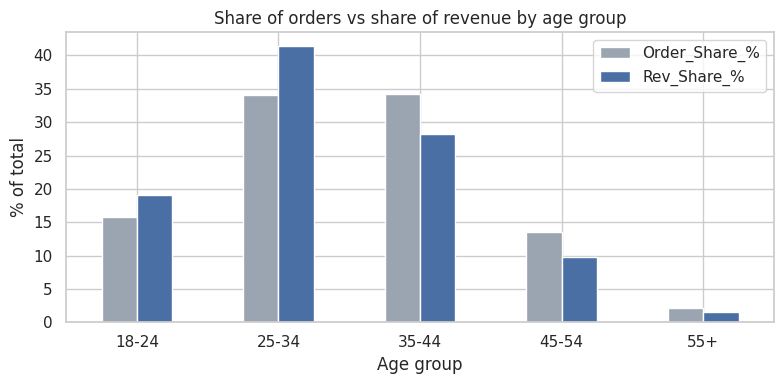

In [33]:
a = d.groupby('Age_Group', observed=True).agg(Orders=('Transaction_ID','size'),
      Revenue=('Total_Revenue','sum'), AOV=('Total_Revenue','mean'))
a['Rev_Share_%'] = (a['Revenue']/a['Revenue'].sum()*100).round(1)
a['Order_Share_%'] = (a['Orders']/a['Orders'].sum()*100).round(1)
print(a)
print((pd.crosstab(d['Age_Group'], d['Product_Category'], normalize='index')*100).round(0))
print(d.groupby(['Age_Group','Product_Category'], observed=True)['Total_Revenue'].mean().unstack().round(0))

a[['Order_Share_%','Rev_Share_%']].plot(kind='bar', figsize=(8,4), color=[GREY, BLUE])
plt.ylabel('% of total'); plt.xlabel('Age group'); plt.xticks(rotation=0)
plt.title('Share of orders vs share of revenue by age group'); plt.tight_layout(); plt.show()

          Orders      Revenue    AOV  Rating
Location                                    
Germany     8360 5,194,920.99 621.40    3.35
India       8281 5,358,785.96 647.12    3.32
Pakistan    8377 5,315,215.53 634.50    3.33
UAE         8289 5,471,965.67 660.15    3.31
UK          8345 5,318,418.30 637.32    3.33
USA         8348 5,467,029.99 654.89    3.33
            Orders       Revenue    AOV  Rating
Gender                                         
Female       22753 14,635,439.99 643.23    3.32
Male         22397 14,404,933.52 643.16    3.34
Non-binary    4850  3,085,962.93 636.28    3.33
                Orders       Revenue    AOV  Rating
Payment_Method                                     
Bank Transfer     7530  4,876,594.63 647.62    3.32
Credit Card      24950 16,005,504.93 641.50    3.33
Crypto            2468  1,616,014.59 654.79    3.30
PayPal           15052  9,628,222.29 639.66    3.34


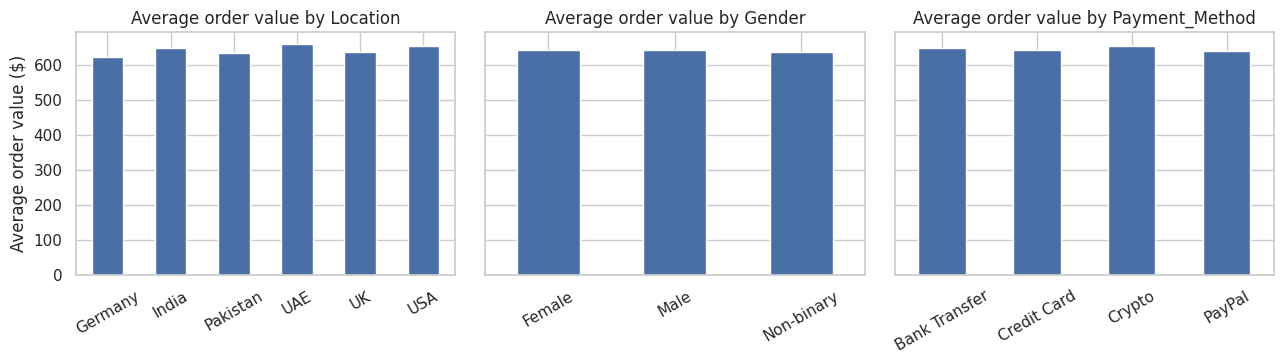

In [34]:
for col in ['Location','Gender','Payment_Method']:
    print(d.groupby(col).agg(Orders=('Transaction_ID','size'), Revenue=('Total_Revenue','sum'),
          AOV=('Total_Revenue','mean'), Rating=('Customer_Rating','mean')))

fig, axes = plt.subplots(1, 3, figsize=(13,3.8), sharey=True)
for ax, col in zip(axes, ['Location','Gender','Payment_Method']):
    d.groupby(col)['Total_Revenue'].mean().plot(kind='bar', ax=ax, color=BLUE)
    ax.set_title(f'Average order value by {col}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('Average order value ($)')
plt.tight_layout(); plt.show()

      Orders       Revenue  YoY_%
Year                             
2023   14970  9,681,257.51    NaN
2024   14883  9,593,293.11  -0.90
2025   15282 10,038,424.72   4.60
      Orders      Revenue  YoY_%
Year                            
2023    4695 2,486,169.09    NaN
2024    4843 2,714,568.11   9.20
2025    4919 2,719,840.42   0.20
2026    4837 2,791,752.45   2.60


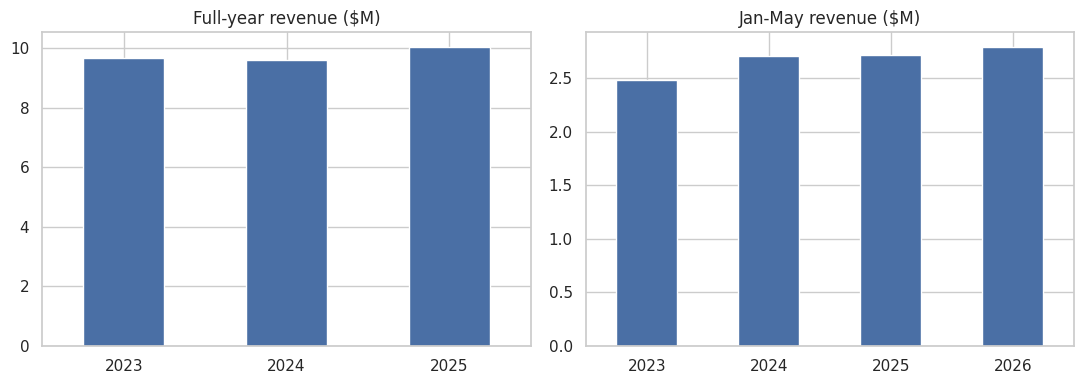

In [35]:
y = d[d['Year'] <= 2025].groupby('Year').agg(Orders=('Transaction_ID','size'), Revenue=('Total_Revenue','sum'))
y['YoY_%'] = (y['Revenue'].pct_change()*100).round(1)
print(y)
ytd = d[d['Month_Num'] <= 5].groupby('Year').agg(Orders=('Transaction_ID','size'), Revenue=('Total_Revenue','sum'))
ytd['YoY_%'] = (ytd['Revenue'].pct_change()*100).round(1)
print(ytd)

fig, axes = plt.subplots(1, 2, figsize=(11,4))
(y['Revenue']/1e6).plot(kind='bar', ax=axes[0], color=BLUE); axes[0].set_title('Full-year revenue ($M)')
(ytd['Revenue']/1e6).plot(kind='bar', ax=axes[1], color=BLUE); axes[1].set_title('Jan-May revenue ($M)')
for ax in axes: ax.set_xlabel(''); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

In [36]:
no_out = d[~d['Revenue_Outlier']]
for name, x in [('All orders', d), ('Without outliers', no_out)]:
    f = x[x['Date'] < '2026-01-01']
    peak = f.loc[f['Season']=='Peak (Nov-Dec)','Total_Revenue'].sum() / f['Total_Revenue'].sum() * 100
    elec = x.loc[x['Product_Category']=='Electronics','Total_Revenue'].sum() / x['Total_Revenue'].sum() * 100
    late = x.loc[x['Delivery_Status'].str.startswith('Late'),'Customer_Rating'].mean()
    ontime = x.loc[x['Delivery_Status'].str.startswith('On time'),'Customer_Rating'].mean()
    print(f"{name:17s} | Peak share {peak:.1f}% | Electronics share {elec:.1f}% | Rating late {late:.2f} vs on-time {ontime:.2f}")

All orders        | Peak share 44.5% | Electronics share 77.3% | Rating late 2.03 vs on-time 3.98
Without outliers  | Peak share 41.8% | Electronics share 77.2% | Rating late 2.03 vs on-time 3.98
